# Tutorial 9. A flywheel energy store from the fundamental elements

![A flywheel energy store](../tutorials/images/t09_hero.png)

**Scope:** energy storage. **Components:** `Storage`, `Dissipator`, `Source`,
`Reference`, `Transformer`, `Gyrator` from `otwin.components.fundamental`.

## The asset

A 100 kW flywheel for frequency regulation: a steel rotor in a vacuum housing,
a permanent-magnet motor-generator, and a converter that commands the machine
current. The operator wants to know:

- **Capacity and self-discharge.** How much energy does the rotor hold between
  its speed limits, and how fast does it bleed away through the bearings and the
  residual windage when idle?
- **Round trip.** Charge at full power, hold for ten minutes, discharge at full
  power: how much comes back?

![Energy flow schematic](../tutorials/images/t09_pd.png)

This tutorial uses no named component. Every domain-specific class in the library
(`Capacitor`, `Mass`, `Tank`, `ThermalMass`, ...) is one of six roles written once
in `otwin.components.fundamental`, with the domain as an argument. When the
library has no name for a device, you build it from these.

## Step 1. The six roles

- `Storage(domain, coefficient, kind)`: one state. `kind="across"` stores the
  integral of the through variable (a capacitor, a mass, an inertia).
- `Dissipator(domain, resistance)`: through = across / resistance.
- `Source(domain, value, kind)`: imposes an across or a through variable; `None`
  makes it an input.
- `Reference`: the zero of the across variable.
- `Transformer`, `Gyrator`: lossless couplings, possibly between domains.

The flywheel: a rotational storage (the rotor), a rotational dissipator (bearings
and windage), a transformer to the electrical side (the machine: back-emf k·ω,
torque k·i), an electrical dissipator (the winding) and a current source (the
converter).

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

import otwin
from otwin.components.fundamental import (
    Dissipator,
    Reference,
    Source,
    Storage,
    Transformer,
)

sns.set_theme(style="whitegrid", palette=["#201E1D", "#EC3013", "#4D86A6", "#8A8886"])

J_ROTOR = 9.0  # kg m2: a 230 kg steel disc of 0.28 m radius
W_MAX, W_MIN = 2 * np.pi * 36_000 / 60, 2 * np.pi * 18_000 / 60  # rad/s
C_DRAG = 1.0e-4  # N m s: magnetic bearings and residual windage
K_MACHINE = 0.22  # V s/rad, equal to N m/A
R_WINDING = 0.03  # ohm

rotor = Storage(
    "rotational", J_ROTOR, kind="across", initial=J_ROTOR * W_MIN, name="rotor"
)
drag = Dissipator(
    "rotational", 1 / C_DRAG, name="drag"
)  # resistance = across/through = 1/c
machine = Transformer(
    1 / K_MACHINE, domain_1="electrical", domain_2="rotational", name="machine"
)
winding = Dissipator("electrical", R_WINDING, name="winding")
converter = Source(
    "electrical", None, kind="through", name="converter"
)  # A, an input: + charges
housing = Reference(name="housing")
bus = Reference(name="bus")

flywheel = otwin.System(rotor, drag, machine, winding, converter, housing, bus)
flywheel.connect(converter.p, winding.p)
flywheel.connect(winding.n, machine.p1)
flywheel.connect(machine.p2, rotor.p, drag.p)
flywheel.connect(converter.n, machine.n1, bus.port)
flywheel.connect(machine.n2, rotor.n, drag.n, housing.port)
model = otwin.compile(flywheel)
print(model.summary())
e_max, e_min = 0.5 * J_ROTOR * W_MAX**2, 0.5 * J_ROTOR * W_MIN**2
print(
    f"usable energy between {W_MIN * 60 / 2 / np.pi:.0f} and {W_MAX * 60 / 2 / np.pi:.0f} rpm: {(e_max - e_min) / 3.6e6:.2f} kWh"
)

System: system

Components:
  rotor                        storage [rotational]
  drag                         dissipator [rotational]
  machine                      transformer [electrical]
  winding                      dissipator [electrical]
  converter                    source [electrical]
  housing                      reference [any]
  bus                          reference [any]

States:
  rotor.state                  stored quantity [kg m^2/s]  x0 = 16964.6

Inputs:
  converter                    current [A]

Parameters:
  rotor.coefficient            9            kg m^2
  drag.resistance              10000        N m s
  machine.ratio                4.54545      
  winding.resistance           0.03         ohm

Outputs: 20 named quantities (model.outputs())
Representation: port-hamiltonian
Backend: rust
usable energy between 18000 and 36000 rpm: 13.32 kWh


One state, the rotor's angular momentum, and one input, the converter current.
The usable energy is the difference of ½Jω² at the two speed limits; a flywheel
never runs down to zero because the power electronics cannot work at low voltage.
The model is `port-hamiltonian`: every element here is power-conjugate, so the
energy audit is a first-law statement.

## Step 2. Idle: self-discharge

Start at full speed with the converter open (zero current) and let the drag act
for an hour.

In [ ]:
t_idle = np.arange(0, 3600 + 1, 1.0)
full = model.with_parameters()
idle = full.simulate(t=t_idle, x0=np.array([J_ROTOR * W_MAX]), inputs={"converter": 0.0})
w = idle["rotor.state"] / J_ROTOR
tau_mech = J_ROTOR / C_DRAG
print(
    f"speed after 1 h: {w[-1] * 60 / 2 / np.pi:.0f} rpm from {W_MAX * 60 / 2 / np.pi:.0f}; "
    f"closed form w0 exp(-t c/J) = {W_MAX * np.exp(-3600 / tau_mech) * 60 / 2 / np.pi:.0f} rpm"
)
print(
    f"energy lost in 1 h: {(idle.energy[0] - idle.energy[-1]) / 3.6e6:.2f} kWh of {idle.energy[0] / 3.6e6:.2f} kWh "
    f"({(1 - idle.energy[-1] / idle.energy[0]):.1%}); time constant J/c = {tau_mech / 3600:.1f} h"
)

speed after 1 h: 34588 rpm from 36000; closed form w0 exp(-t c/J) = 34588 rpm
energy lost in 1 h: 1.37 kWh of 17.77 kWh (7.7%); time constant J/c = 25.0 h


The speed decays exponentially with the time constant J/c and the model matches
the closed form. The energy loss in an hour is the self-discharge figure the
data sheet quotes; it is why flywheels serve minutes-to-hours applications, not
days.

## Step 3. A round trip at 100 kW

The converter is current-controlled. To charge at 100 kW the current must follow
P/(k·ω), which grows as the speed falls; we compute it from the state, so the
input is a feedback law. Charge from the lower limit to the upper, hold ten
minutes, discharge back.

In [ ]:
P_RATED = 100e3
t = np.arange(0, 1500 + 1, 0.1)


def converter_current(time, x):
    speed = x[0] / J_ROTOR
    emf = K_MACHINE * speed
    if time < 400:
        return P_RATED / emf if speed < W_MAX else 0.0  # charge until the upper limit
    if time < 1000:
        return 0.0  # hold
    return -P_RATED / emf if speed > W_MIN else 0.0  # discharge until the lower limit


trip = model.simulate(
    t=t, x0=np.array([J_ROTOR * W_MIN]), inputs={"converter": converter_current}
)
i_conv = trip["converter"]
p_bus = trip["converter.voltage"] * i_conv  # power at the converter terminals
charge = (t < 400) & (i_conv > 0)
discharge = (t >= 1000) & (i_conv < 0)
e_in = np.trapezoid(p_bus[charge], t[charge])
e_out = -np.trapezoid(p_bus[discharge], t[discharge])
print(f"charged in {t[charge][-1]:.0f} s, discharged in {t[discharge][-1] - 1000:.0f} s")
print(
    f"energy in {e_in / 3.6e6:.2f} kWh, energy out {e_out / 3.6e6:.2f} kWh: round-trip efficiency {e_out / e_in:.1%}"
)
print(
    f"losses: winding {np.trapezoid(trip['winding.power'], t) / 3.6e6:.3f} kWh, drag {np.trapezoid(trip['drag.power'], t) / 3.6e6:.3f} kWh"
)
print(
    f"converter current: {i_conv[charge].min():.0f} to {i_conv[charge].max():.0f} A while charging"
)

charged in 400 s, discharged in 386 s
energy in 11.21 kWh, energy out 10.64 kWh: round-trip efficiency 94.9%
losses: winding 0.192 kWh, drag 0.389 kWh
converter current: 129 to 241 A while charging


The round-trip efficiency is set by two losses: I²R in the winding during the
power phases, and drag all the time, mostly during the hold. The current the
converter must supply is largest at low speed, where the back-emf is smallest,
which sizes the power electronics.

## Step 4. Plot the round trip

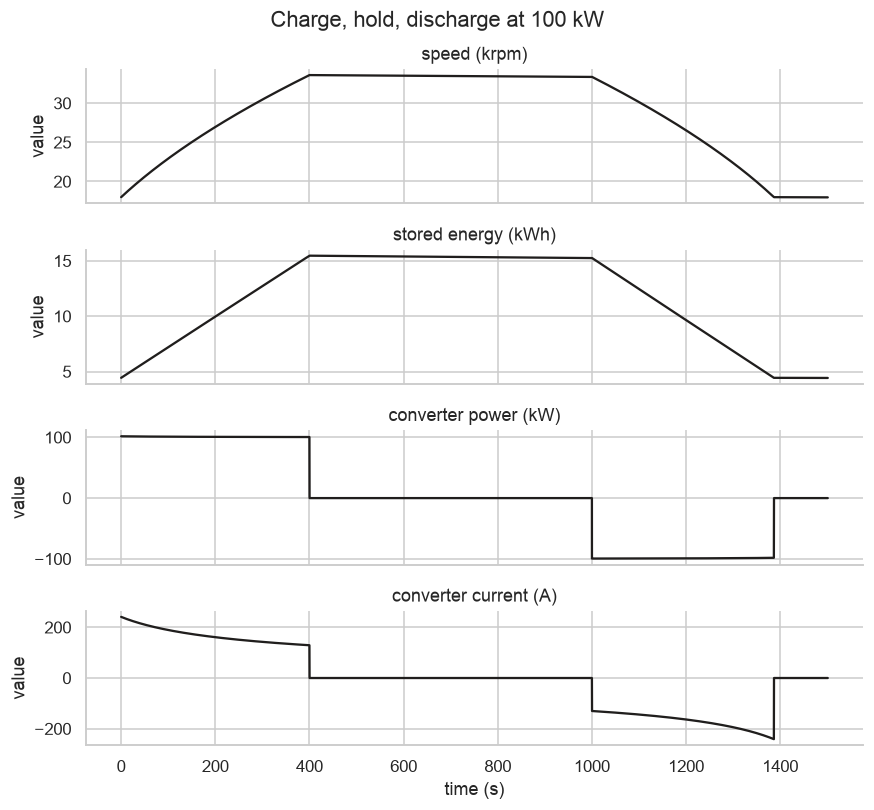

In [ ]:
frame = pd.DataFrame(
    {
        "time (s)": t,
        "speed (krpm)": trip["rotor.state"] / J_ROTOR * 60 / 2 / np.pi / 1e3,
        "stored energy (kWh)": trip.energy / 3.6e6,
        "converter power (kW)": p_bus / 1e3,
        "converter current (A)": i_conv,
    }
)
long = frame.melt("time (s)", var_name="signal", value_name="value")
g = sns.relplot(
    data=long,
    x="time (s)",
    y="value",
    row="signal",
    kind="line",
    height=1.8,
    aspect=4.5,
    facet_kws={"sharey": False},
    color="#201E1D",
)
g.set_titles("{row_name}")
g.figure.suptitle("Charge, hold, discharge at 100 kW", y=1.02)

The stored energy rises linearly at constant power, sags during the hold (the
self-discharge), and falls linearly on discharge; the speed follows the square
root of the energy. The current trace shows the converter working hardest at
the low-speed ends.

## Step 5. The energy audit

Every element in this model is power-conjugate, so the first law can be checked
directly: the change in stored energy over the trip equals the integral of the
converter power less the two losses. The small difference is bookkeeping, not
physics: a feedback input is held over each step, so at the two instants the
converter switches, the recorded power and the power the step used differ by
one step's worth.

In [ ]:
delta_e = trip.energy[-1] - trip.energy[0]
integral = np.trapezoid(p_bus - trip["winding.power"] - trip["drag.power"], t)
print(
    f"stored energy changed by {delta_e / 3.6e6:.4f} kWh; integral of (P_conv - P_winding - P_drag) = {integral / 3.6e6:.4f} kWh"
)
print(
    f"difference {abs(delta_e - integral) / 1e3:.1f} kJ; one step of rated power is {P_RATED * 0.1 / 1e3:.1f} kJ, "
    f"and the converter switches twice"
)

stored energy changed by -0.0125 kWh; integral of (P_conv - P_winding - P_drag) = -0.0156 kWh
difference 11.2 kJ; one step of rated power is 10.0 kJ, and the converter switches twice


## What to take from this

- The whole library is six roles with a domain argument; a device the library
  does not name is a few lines of these.
- `Transformer` between electrical and rotational is the electric machine in
  Otwin's convention; the ratio is 1/k.
- A current-controlled converter is a through source with a feedback law.

Next: [Tutorial 10](10_from_model_to_twin.md) turns a model into a twin: fit,
forecast, audit.